# 10 Years of FAIR Principles: How Biomedical Data Sharing Evolved (2011–2025)

> **Research question:** Did the publication of the FAIR principles (Wilkinson et al., *Scientific Data*, March 2016)
> durably shift how biomedical researchers share data — and which sharing practices improved most?

This notebook analyses the full output of a four-stage extraction and assessment pipeline applied to
PubMed Central (PMC) articles published between 2011 and 2025. Each stage contributed:

| Stage | Script | What it produced |
|-------|--------|-----------------|
| 1 | `fetch_pmc.py` | PMC XML for articles with data availability signals |
| 2 | `pubmed_to_sqlite.py` | Structured SQLite DB: articles, DAS text, supplementary files, accession numbers |
| 3 | `classify_repositories.py` | Repository infrastructure-tier classification for every URL in a DAS |
| 4 | `categorise_das.py` | Primary DAS category + data-sharing score (0–10) per article |
| 5 | `assess_fuji.py` | F-UJI automated FAIR assessment for gold/silver repository URLs |

The FAIR principles were published in **March 2016**. All year-over-year analyses use this as the
natural before/after watershed.

---


In [1]:
import importlib.util, subprocess, sys

# A bare `pip install ...` here resolves to whatever `pip` is first on
# $PATH, not this kernel's own interpreter -- in this environment that is
# a separate, PEP-668 "externally managed" pip that refuses to run at all,
# even when every package below is already installed in this kernel's own
# venv. Check first, and if actually needed, install via
# `sys.executable -m pip` so it always targets this kernel's environment
# instead of whatever's on PATH.
_required = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy']
_import_name = {}
_missing = [pkg for pkg in _required
            if importlib.util.find_spec(_import_name.get(pkg, pkg.replace("-", "_"))) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing])
else:
    print("Required packages already installed.")

Required packages already installed.


## 0 · Setup

**Publication year used in this analysis.** `article.year` is a precomputed, persisted
column — not `pub_year` (PMC's own field is unreliable; see below) and not something this
notebook derives itself. It's produced by `pipeline/derive_year.py`, which is the single
source of truth for the derivation logic, the full rationale, and validation numbers. In
short: `pub_year` mixes print-issue and online-first dates inconsistently across publishers,
so the script anchors on `pub_year` but defers to `epub_date` when they're within 1 year of
each other (the common online-first-vs-print-issue lag), falls back to `epub_date` alone or
`accepted_date`/`received_date` when `pub_year` is missing, and leaves `year` `NULL` for the
~0.06% of articles with no usable date at all. Run that script whenever the corpus is
extended with new data; every notebook here just reads `article.year` directly.

In [2]:
import sqlite3, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from pathlib import Path

warnings.filterwarnings("ignore")

# ── Style ──────────────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", font_scale=1.15)
PALETTE   = sns.color_palette("tab10")
FAIR_YEAR = 2016          # FAIR principles published
FIG_W, FIG_H = 13, 5     # default figure width / height

# ── Database ───────────────────────────────────────────────────────────────
DB_PATH = Path("../data/processed/pmc_fair.db")    # adjust if your DB is elsewhere
assert DB_PATH.exists(), f"Database not found: {DB_PATH}"
FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SAVEFIG_KWARGS = dict(dpi=150, bbox_inches="tight")

con = sqlite3.connect(DB_PATH)
con.row_factory = sqlite3.Row

def q(sql, params=()):
    """Run a query and return a DataFrame."""
    return pd.read_sql_query(sql, con, params=params)

# Verify all pipeline tables are present
tables = {r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'").fetchall()}
required = {"article","data_availability","das_category","repo_classification","accession_number","supplementary_material"}
missing  = required - tables
if missing:
    print(f"⚠️  Missing tables (run corresponding pipeline stages): {missing}")
else:
    print("✅ All pipeline tables present")

HAS_FUJI = "fuji_assessment" in tables
print(f"   F-UJI assessment data: {'✅ present' if HAS_FUJI else '⚠️  not yet run (Stage 5)'}")

# `article.year` is precomputed by pipeline/derive_year.py (pub_year anchor,
# epub_date only within +/-1 year, accepted_date/received_date as a last-resort
# fallback) -- see that script for the full derivation logic and rationale.
# This notebook just reads it directly; it doesn't recompute anything.
assert 'year' in {r[1] for r in con.execute("PRAGMA table_info(article)").fetchall()}, \
    "article.year not found -- run `python pipeline/derive_year.py --db <path>` first"


✅ All pipeline tables present
   F-UJI assessment data: ✅ present


---
## 1 · Corpus Overview

Before any trend analysis, we characterise the corpus: how many articles per year,
how many carry an explicit Data Availability Statement (DAS), and how the presence
of supplementary materials and inline accession numbers distributes across the timeline.


In [3]:
# ── 1.1 Article counts per year ────────────────────────────────────────────
df_corpus = q("""
    SELECT
        a.year                              AS year,
        COUNT(*)                                AS total_articles,
        SUM(CASE WHEN da.da_id IS NOT NULL THEN 1 ELSE 0 END)  AS has_das,
        SUM(CASE WHEN sm.article_id IS NOT NULL THEN 1 ELSE 0 END) AS has_supp,
        SUM(CASE WHEN ac.article_id IS NOT NULL THEN 1 ELSE 0 END) AS has_accession
    FROM article a
    LEFT JOIN data_availability da ON da.article_id = a.article_id
    LEFT JOIN (SELECT DISTINCT article_id FROM supplementary_material) sm
              ON sm.article_id = a.article_id
    LEFT JOIN (SELECT DISTINCT article_id FROM accession_number) ac
              ON ac.article_id = a.article_id
    WHERE a.year BETWEEN 2011 AND 2025
    GROUP BY a.year ORDER BY a.year
""")

df_corpus["pct_das"]  = df_corpus.has_das  / df_corpus.total_articles * 100
df_corpus["pct_supp"] = df_corpus.has_supp / df_corpus.total_articles * 100
df_corpus["pct_acc"]  = df_corpus.has_accession / df_corpus.total_articles * 100

df_corpus["year"] = df_corpus["year"].astype(int)
print(df_corpus.to_string(index=False))


 year  total_articles  has_das  has_supp  has_accession   pct_das  pct_supp   pct_acc
 2011          110347     1969     28047          83548  1.784371 25.417093 75.713884
 2012          148267     3148     37905         112400  2.123197 25.565365 75.809182
 2013          187212     2475     49451         142604  1.322031 26.414439 76.172468
 2014          223496    15125     61269         169217  6.767459 27.413913 75.713659
 2015          252745    35779     68732         190459 14.156165 27.194208 75.356189
 2016          277445    50691     86673         212901 18.270648 31.239705 76.736290
 2017          318654    73658    113305         249008 23.115354 35.557376 78.143692
 2018          349018    90931    134304         273649 26.053384 38.480537 78.405412
 2019          414163   124653    164295         324915 30.097570 39.669164 78.450996
 2020          595499   183673    226286         455664 30.843545 37.999392 76.518013
 2021          734002   372092    291556         57776

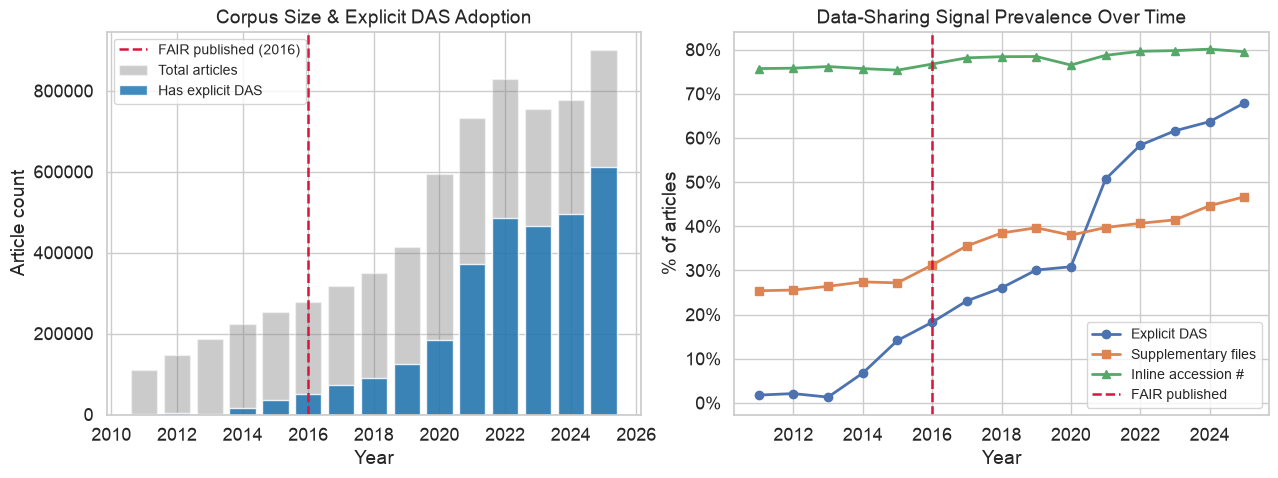

Saved → ../figures/fig_corpus_01_overview.png


In [4]:
# ── 1.2 Plot: corpus size + DAS adoption ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

# Left: stacked bar — total articles with DAS overlay
ax = axes[0]
ax.bar(df_corpus.year, df_corpus.total_articles, color=PALETTE[7], alpha=0.4, label="Total articles")
ax.bar(df_corpus.year, df_corpus.has_das,         color=PALETTE[0], alpha=0.85, label="Has explicit DAS")
ax.axvline(FAIR_YEAR, color="crimson", lw=1.8, ls="--", label="FAIR published (2016)")
ax.set_xlabel("Year"); ax.set_ylabel("Article count")
ax.set_title("Corpus Size & Explicit DAS Adoption")
ax.legend(fontsize=10)

# Right: % of articles with each data-sharing signal
ax = axes[1]
ax.plot(df_corpus.year, df_corpus.pct_das,  marker="o", lw=2, label="Explicit DAS")
ax.plot(df_corpus.year, df_corpus.pct_supp, marker="s", lw=2, label="Supplementary files")
ax.plot(df_corpus.year, df_corpus.pct_acc,  marker="^", lw=2, label="Inline accession #")
ax.axvline(FAIR_YEAR, color="crimson", lw=1.8, ls="--", label="FAIR published")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Year"); ax.set_ylabel("% of articles")
ax.set_title("Data-Sharing Signal Prevalence Over Time")
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_corpus_01_overview.png", **SAVEFIG_KWARGS)
plt.show()
print(f"Saved → {FIGURES_DIR / 'fig_corpus_01_overview.png'}")


---
## 2 · Data Availability Statement Categories Over Time

Stage 4 assigned every article one of nine primary categories (ordered here by FAIR compliance).
This section shows the **compositional shift** — what proportion of articles fall into each
category each year — and spotlights the two most policy-relevant signals:
`available_on_request` (restrictive) and `repository_named` (best practice).


In [5]:
# ── 2.1 Category counts per year ────────────────────────────────────────────
CAT_ORDER = [
    "repository_named", "accession_provided", "no_das_but_accession",
    "open_unspecified", "supplementary_only",  "no_das_but_supp",
    "available_on_request", "restricted",      "no_statement",
]
CAT_LABELS = {
    "repository_named":      "Named repository",
    "accession_provided":    "Accession # in DAS",
    "no_das_but_accession":  "Accession (no DAS)",
    "open_unspecified":      "Open (unspecified)",
    "supplementary_only":    "Supplementary only",
    "no_das_but_supp":       "Supp. (no DAS)",
    "available_on_request":  "Available on request ⚠️",
    "restricted":            "Restricted",
    "no_statement":          "No statement",
}
# Colour: green shades = higher data-sharing score categories, amber = neutral, red = restrictive
CAT_COLOURS = {
    "repository_named":      "#2ca02c",
    "accession_provided":    "#98df8a",
    "no_das_but_accession":  "#b5cf6b",
    "open_unspecified":      "#aec7e8",
    "supplementary_only":    "#ffbb78",
    "no_das_but_supp":       "#ffd8b1",
    "available_on_request":  "#d62728",
    "restricted":            "#ff9896",
    "no_statement":          "#c7c7c7",
}

df_cat = q("""
    SELECT a.year AS year, dc.primary_category AS category, COUNT(*) AS n
    FROM das_category dc
    JOIN article a ON a.article_id = dc.article_id
    WHERE a.year BETWEEN 2011 AND 2025
    GROUP BY a.year, dc.primary_category
    ORDER BY a.year, dc.primary_category
""")

pivot = df_cat.pivot(index="year", columns="category", values="n").fillna(0)
pivot.index = pivot.index.astype(int)
# Reorder columns
pivot = pivot.reindex([c for c in CAT_ORDER if c in pivot.columns], axis=1)
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

print("Category counts per year:")
print(pivot.astype(int).to_string())


Category counts per year:
category  repository_named  accession_provided  no_das_but_accession  open_unspecified  supplementary_only  no_das_but_supp  available_on_request  restricted  no_statement
year                                                                                                                                                                       
2011                   132                  24                 81723              1689                  14             1776                    77          33         24879
2012                   357                  43                109685              2502                  67             2369                   138          41         33065
2013                   780                  33                140653              1302                 145             3643                   174          41         40441
2014                  3050                 203                154873             10564                 445        

In [ ]:
# -- 2.2 Compositional shift -- percentage and absolute counts, combined --
# Daniel: "Perhaps combine both plots into one figure? This is the essence
# of the paper and deserves some space." -- then: "we want this two absolute
# and percentage as 1 figure but below each other" -- then: "put absolute on
# top and percentage on bottom". Two panels stacked vertically, sharing the
# x-axis and one legend below both.
fig, axes = plt.subplots(2, 1, figsize=(FIG_W, (FIG_H + 1) * 2), sharex=True)

# Top: absolute counts (same pivot table, before the %-normalisation into
# pivot_pct, so growth driven by the corpus itself stays visible)
ax = axes[0]
bottom = np.zeros(len(pivot))
for cat in pivot.columns:
    vals = pivot[cat].values
    ax.bar(pivot.index, vals, bottom=bottom,
           color=CAT_COLOURS.get(cat, "#888"), label=CAT_LABELS.get(cat, cat),
           edgecolor="white", linewidth=0.4)
    bottom += vals
ax.axvline(FAIR_YEAR - 0.5, color="crimson", lw=2, ls="--", label="FAIR published (2016)")
ax.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda v, _: f"{v/1e3:.0f}k" if v >= 1000 else str(int(v))))
ax.set_ylabel("Number of articles")
ax.set_title("Compositional Shift (absolute counts)")

# Bottom: percentage composition
ax = axes[1]
bottom = np.zeros(len(pivot_pct))
for cat in pivot_pct.columns:
    vals = pivot_pct[cat].values
    ax.bar(pivot_pct.index, vals, bottom=bottom,
           color=CAT_COLOURS.get(cat, "#888"), label=CAT_LABELS.get(cat, cat),
           edgecolor="white", linewidth=0.4)
    bottom += vals
ax.axvline(FAIR_YEAR - 0.5, color="crimson", lw=2, ls="--", label="FAIR published (2016)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Publication Year"); ax.set_ylabel("% of articles")
ax.set_title("Compositional Shift (% of articles)")
ax.set_xticks(pivot_pct.index)
ax.set_xticklabels(pivot_pct.index, rotation=45, fontsize=9)

# One shared legend for both panels, placed below rather than repeated
# twice or pushed out to the side.
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.0),
           ncol=5, fontsize=9, frameon=True)
fig.suptitle("Compositional Shift in Data-Sharing Practices (2011\u20132025)", fontsize=14)
plt.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.savefig(FIGURES_DIR / "fig_corpus_02_das_composition.png", **SAVEFIG_KWARGS)
plt.show()
print(f"Saved -> {FIGURES_DIR / 'fig_corpus_02_das_composition.png'} (combined %/absolute figure, stacked, absolute on top)")

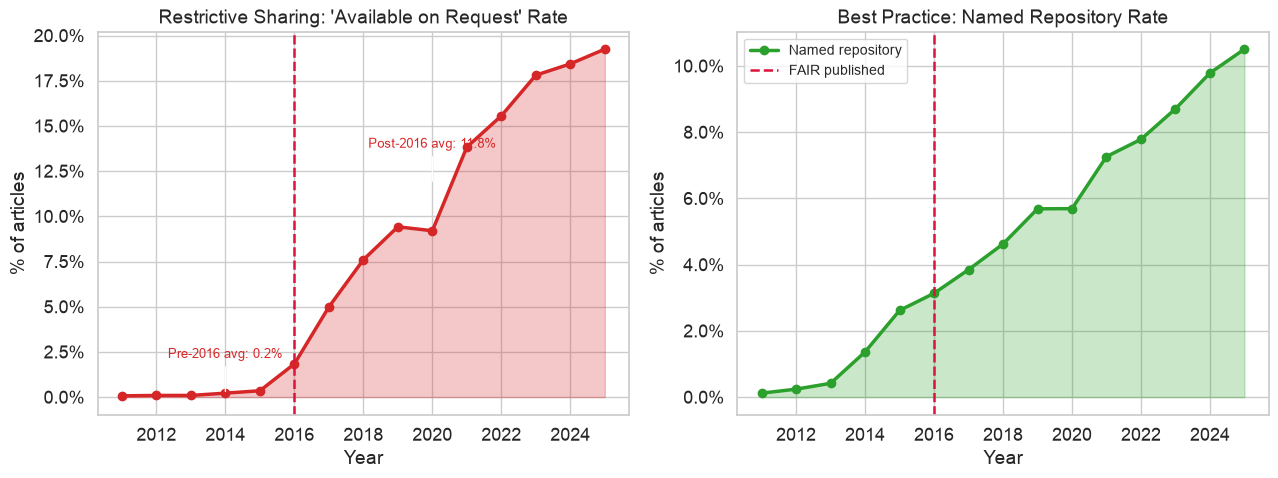

In [7]:
# ── 2.3 Restrictive-sharing spotlight: "available on request" ────────────────────────
df_req = pivot_pct[["available_on_request"]].copy() if "available_on_request" in pivot_pct else pd.DataFrame()
df_repo = pivot_pct[["repository_named"]].copy() if "repository_named" in pivot_pct else pd.DataFrame()

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

if not df_req.empty:
    ax = axes[0]
    ax.fill_between(df_req.index, df_req.available_on_request,
                    color="#d62728", alpha=0.25)
    ax.plot(df_req.index, df_req.available_on_request,
            color="#d62728", lw=2.5, marker="o", label="Available on request")
    ax.axvline(FAIR_YEAR, color="crimson", ls="--", lw=1.8)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title("Restrictive Sharing: 'Available on Request' Rate")
    ax.set_xlabel("Year"); ax.set_ylabel("% of articles")

    # Annotate before/after means
    before = df_req[df_req.index < FAIR_YEAR].available_on_request.mean()
    after  = df_req[df_req.index >= FAIR_YEAR].available_on_request.mean()
    ax.annotate(f"Pre-2016 avg: {before:.1f}%", xy=(2014, before),
                fontsize=9, color="#d62728", ha="center",
                xytext=(2014, before + 2), arrowprops=dict(arrowstyle="-"))
    ax.annotate(f"Post-2016 avg: {after:.1f}%", xy=(2020, after),
                fontsize=9, color="#d62728", ha="center",
                xytext=(2020, after + 2), arrowprops=dict(arrowstyle="-"))

if not df_repo.empty:
    ax = axes[1]
    ax.fill_between(df_repo.index, df_repo.repository_named,
                    color="#2ca02c", alpha=0.25)
    ax.plot(df_repo.index, df_repo.repository_named,
            color="#2ca02c", lw=2.5, marker="o", label="Named repository")
    ax.axvline(FAIR_YEAR, color="crimson", ls="--", lw=1.8, label="FAIR published")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title("Best Practice: Named Repository Rate")
    ax.set_xlabel("Year"); ax.set_ylabel("% of articles")
    ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_corpus_03_restrictive_vs_best.png", **SAVEFIG_KWARGS)
plt.show()


---
## 3 · Data-Sharing Score Trend (Stage 4 Score, 0–10)

Stage 4 assigned each article a data-sharing score (0–10) based on its DAS category
and secondary signals (DOI present, license mentioned, URL present).
This section tests whether mean scores increased after 2016 and estimates the
effect size of the FAIR principles publication.


In [ ]:
# ── 3.1 Mean data-sharing score per year with 95% CI ────────────────────────
df_score = q("""
    SELECT a.year AS year, dc.data_sharing_score
    FROM das_category dc
    JOIN article a ON a.article_id = dc.article_id
    WHERE a.year BETWEEN 2011 AND 2025
""")

df_score["year"] = df_score["year"].astype(int)
score_stats = (df_score.groupby("year")["data_sharing_score"]
               .agg(mean="mean", std="std", n="count")
               .reset_index())
score_stats["se"]  = score_stats["std"] / np.sqrt(score_stats["n"])
score_stats["ci95"] = 1.96 * score_stats["se"]

# ── Mann-Whitney U: pre vs post FAIR ────────────────────────────────────────
pre  = df_score[df_score.year <  FAIR_YEAR]["data_sharing_score"]
post = df_score[df_score.year >= FAIR_YEAR]["data_sharing_score"]
# alternative="greater": testing pre > post (the actual direction of the observed decline)
u_stat, p_val = stats.mannwhitneyu(pre, post, alternative="greater")
# u_stat/(n1*n2) is the common-language effect size (CLES, here P(a random
# pre-FAIR score > a random post-FAIR score)), NOT the rank-biserial
# correlation r -- CLES=0.5 is the null point, not 0, so Cohen's-d-style
# thresholds (<0.1 negligible ... >0.5 large) don't apply to it directly.
# True rank-biserial r = 2*CLES - 1.
cles     = u_stat / (len(pre) * len(post))
r_effect = 2 * cles - 1
print(f"Pre-FAIR  mean score : {pre.mean():.3f}  (n={len(pre):,})")
print(f"Post-FAIR mean score : {post.mean():.3f}  (n={len(post):,})")
print(f"Mann-Whitney U={u_stat:.0f}, p={p_val:.4e}, effect r={r_effect:.3f}")


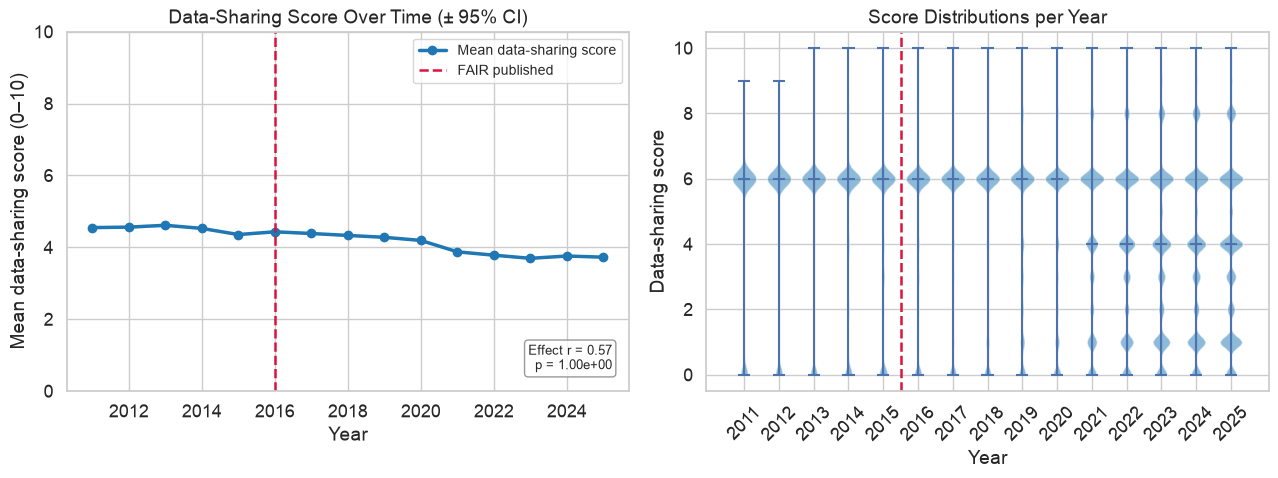

In [9]:
# ── 3.2 Plot: mean data-sharing score + violin distributions ────────────────
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

# Left: mean + CI ribbon
ax = axes[0]
ax.fill_between(score_stats.year,
                score_stats["mean"] - score_stats.ci95,
                score_stats["mean"] + score_stats.ci95,
                alpha=0.2, color=PALETTE[0])
ax.plot(score_stats.year, score_stats["mean"],
        marker="o", lw=2.5, color=PALETTE[0], label="Mean data-sharing score")
ax.axvline(FAIR_YEAR, color="crimson", lw=1.8, ls="--", label="FAIR published")
ax.set_xlabel("Year"); ax.set_ylabel("Mean data-sharing score (0–10)")
ax.set_title("Data-Sharing Score Over Time (± 95% CI)")
ax.set_ylim(0, 10); ax.legend(fontsize=10)

# Annotate effect
p_label = "p < 0.001" if p_val < 1e-3 else f"p = {p_val:.2e}"
ax.annotate(f"Effect r = {r_effect:.2f}\n{p_label}",
            xy=(0.97, 0.05), xycoords="axes fraction",
            ha="right", va="bottom", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="grey", alpha=0.8))

# Right: violin per year (every 2 years for readability)
ax = axes[1]
years_sample = sorted(df_score.year.unique())
data_violin  = [df_score[df_score.year == yr]["data_sharing_score"].values
                for yr in years_sample]
vp = ax.violinplot(data_violin, positions=years_sample,
                   showmedians=True, widths=0.7)
for body in vp["bodies"]:
    body.set_facecolor(PALETTE[0]); body.set_alpha(0.5)
ax.axvline(FAIR_YEAR - 0.5, color="crimson", lw=1.8, ls="--")
ax.set_xlabel("Year"); ax.set_ylabel("Data-sharing score")
ax.set_title("Score Distributions per Year")
ax.set_xticks(years_sample)
ax.set_xticklabels(years_sample, rotation=45)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_corpus_04_fair_score_trend.png", **SAVEFIG_KWARGS)
plt.show()


---
## 4 · Repository Landscape

Stage 3 classified every URL in a DAS by repository type and infrastructure tier.
This section answers: *Which repositories are researchers actually using, and
how has the repository ecosystem evolved?*


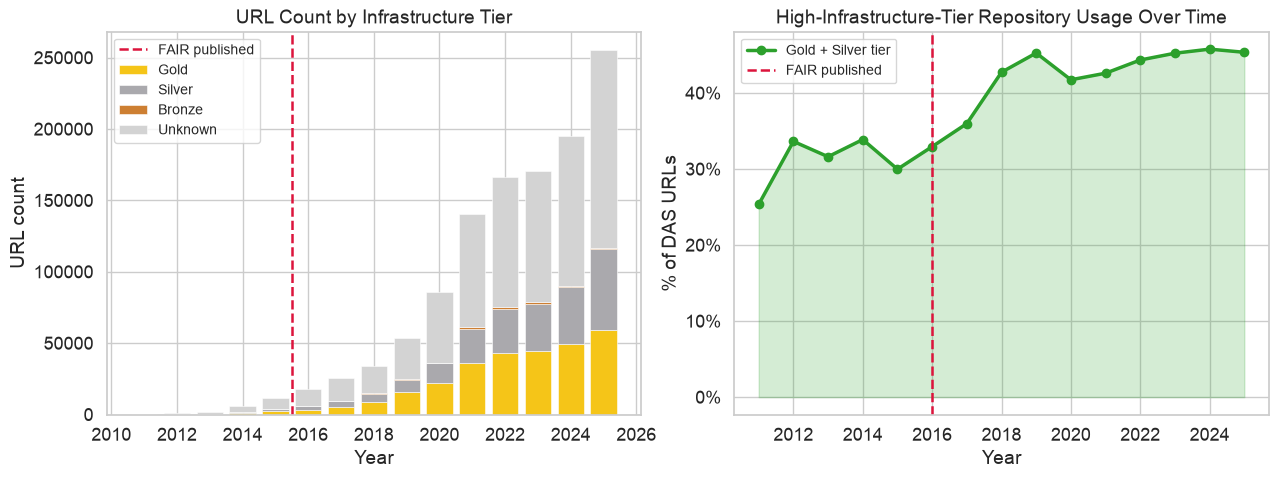

In [10]:
# ── 4.1 Repository infrastructure tier distribution per year ────────────────
df_tier = q("""
    SELECT a.year AS year, rc.repo_infra_tier, COUNT(*) AS n
    FROM repo_classification rc
    JOIN da_link dl ON dl.link_id = rc.link_id
    JOIN data_availability da ON da.da_id = dl.da_id
    JOIN article a ON a.article_id = da.article_id
    WHERE a.year BETWEEN 2011 AND 2025
    GROUP BY a.year, rc.repo_infra_tier ORDER BY a.year
""")

tier_pivot = df_tier.pivot(index="year", columns="repo_infra_tier", values="n").fillna(0)
tier_pivot.index = tier_pivot.index.astype(int)
tier_pct   = tier_pivot.div(tier_pivot.sum(axis=1), axis=0) * 100

TIER_COLOURS = {"gold": "#f5c518", "silver": "#aaa9ad", "bronze": "#cd7f32", "unknown": "#d3d3d3"}

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

# Left: absolute counts
ax = axes[0]
bottom = np.zeros(len(tier_pivot))
for tier in ["gold", "silver", "bronze", "unknown"]:
    if tier not in tier_pivot: continue
    ax.bar(tier_pivot.index, tier_pivot[tier], bottom=bottom,
           color=TIER_COLOURS[tier], label=tier.capitalize(), edgecolor="white", lw=0.4)
    bottom += tier_pivot[tier].values
ax.axvline(FAIR_YEAR - 0.5, color="crimson", lw=1.8, ls="--", label="FAIR published")
ax.set_title("URL Count by Infrastructure Tier"); ax.set_xlabel("Year"); ax.set_ylabel("URL count")
ax.legend(fontsize=10)

# Right: % gold+silver (high infrastructure tier)
ax = axes[1]
fair_pos = tier_pct.get("gold", pd.Series(0, index=tier_pct.index)) +            tier_pct.get("silver", pd.Series(0, index=tier_pct.index))
ax.fill_between(fair_pos.index, fair_pos.values, color="#2ca02c", alpha=0.2)
ax.plot(fair_pos.index, fair_pos.values, color="#2ca02c", lw=2.5, marker="o",
        label="Gold + Silver tier")
ax.axvline(FAIR_YEAR, color="crimson", lw=1.8, ls="--", label="FAIR published")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("High-Infrastructure-Tier Repository Usage Over Time")
ax.set_xlabel("Year"); ax.set_ylabel("% of DAS URLs")
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_corpus_05_repo_tiers.png", **SAVEFIG_KWARGS)
plt.show()


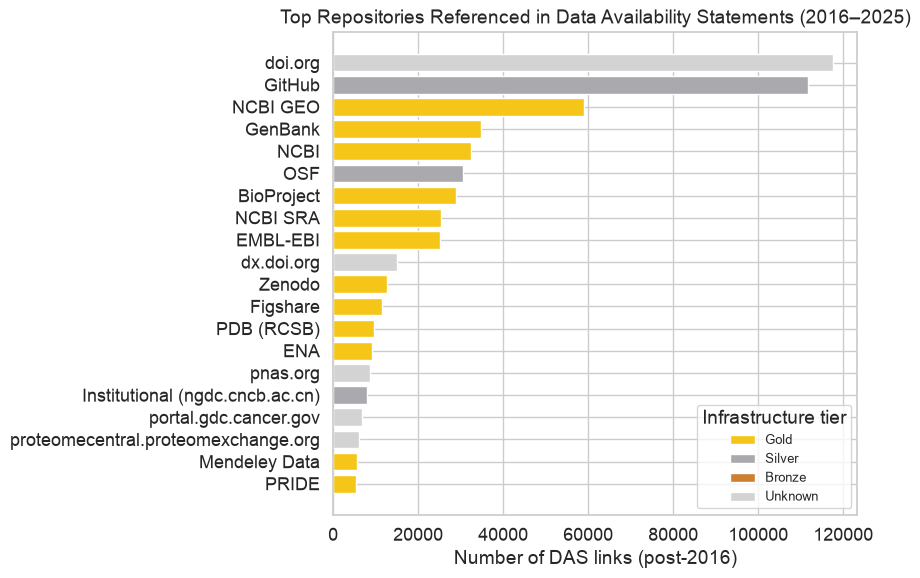

                          repo_name repo_infra_tier      n
                            doi.org         unknown 117466
                             GitHub          silver 111743
                           NCBI GEO            gold  58911
                            GenBank            gold  34795
                               NCBI            gold  32345
                                OSF          silver  30610
                         BioProject            gold  29007
                           NCBI SRA            gold  25308
                           EMBL-EBI            gold  25196
                         dx.doi.org         unknown  15061
                             Zenodo            gold  12733
                           Figshare            gold  11442
                         PDB (RCSB)            gold   9710
                                ENA            gold   9180
                           pnas.org         unknown   8655
    Institutional (ngdc.cncb.ac.cn)          silver   79

In [11]:
# ── 4.2 Top 15 repositories (post-2016) ─────────────────────────────────────
df_repos = q("""
    SELECT rc.repo_name, rc.repo_infra_tier, COUNT(*) AS n
    FROM repo_classification rc
    JOIN da_link dl ON dl.link_id = rc.link_id
    JOIN data_availability da ON da.da_id = dl.da_id
    JOIN article a ON a.article_id = da.article_id
    WHERE a.year >= 2016 AND rc.repo_name IS NOT NULL AND rc.repo_name != ''
    GROUP BY rc.repo_name, rc.repo_infra_tier
    ORDER BY n DESC LIMIT 20
""")

fig, ax = plt.subplots(figsize=(9, 6))
colours  = [TIER_COLOURS.get(t, "#888") for t in df_repos.repo_infra_tier]
bars = ax.barh(df_repos.repo_name[::-1], df_repos.n[::-1], color=colours[::-1], edgecolor="white")
ax.set_xlabel("Number of DAS links (post-2016)")
ax.set_title("Top Repositories Referenced in Data Availability Statements (2016–2025)")

# Legend patches
from matplotlib.patches import Patch
legend_els = [Patch(fc=TIER_COLOURS[t], label=t.capitalize()) for t in ["gold","silver","bronze","unknown"]]
ax.legend(handles=legend_els, title="Infrastructure tier", fontsize=9, loc="lower right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_corpus_06_top_repos.png", **SAVEFIG_KWARGS)
plt.show()
print(df_repos.to_string(index=False))


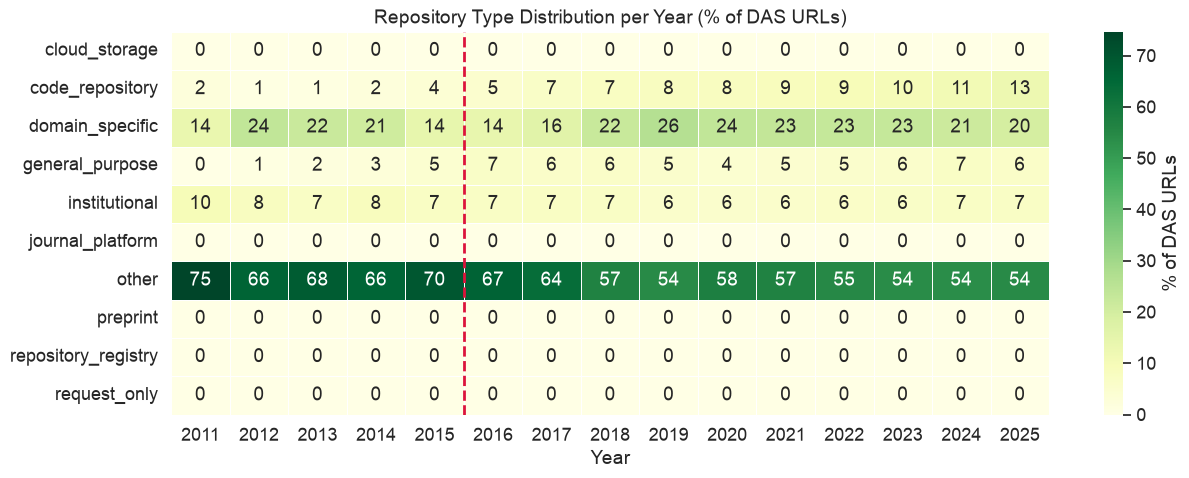

In [12]:
# ── 4.3 Repository type evolution (heatmap) ──────────────────────────────────
df_rtype = q("""
    SELECT a.year AS year, rc.repo_type, COUNT(*) AS n
    FROM repo_classification rc
    JOIN da_link dl ON dl.link_id = rc.link_id
    JOIN data_availability da ON da.da_id = dl.da_id
    JOIN article a ON a.article_id = da.article_id
    WHERE a.year BETWEEN 2011 AND 2025 AND rc.repo_type IS NOT NULL
    GROUP BY a.year, rc.repo_type
""")

rtype_pivot = df_rtype.pivot(index="repo_type", columns="year", values="n").fillna(0)
rtype_pivot.columns = rtype_pivot.columns.astype(int)
rtype_pct   = rtype_pivot.div(rtype_pivot.sum(axis=0), axis=1) * 100  # normalise per year

fig, ax = plt.subplots(figsize=(FIG_W, 5))
sns.heatmap(rtype_pct, annot=True, fmt=".0f", cmap="YlGn", ax=ax,
            linewidths=0.5, cbar_kws={"label": "% of DAS URLs"})
ax.set_title("Repository Type Distribution per Year (% of DAS URLs)")
ax.set_xlabel("Year"); ax.set_ylabel("")
# Mark FAIR publication column
if FAIR_YEAR in rtype_pct.columns:
    col_idx = list(rtype_pct.columns).index(FAIR_YEAR)
    ax.axvline(col_idx, color="crimson", lw=2, ls="--")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_corpus_07_repo_type_heatmap.png", **SAVEFIG_KWARGS)
plt.show()


---
## 5 · Accession Numbers — The Pre-FAIR Sharing Infrastructure

Before explicit DAS sections became common (~2014), most genomics and structural
biology papers shared data via inline accession numbers (GEO, SRA, PDB, GenBank).
This section tracks how that channel evolved alongside the DAS.


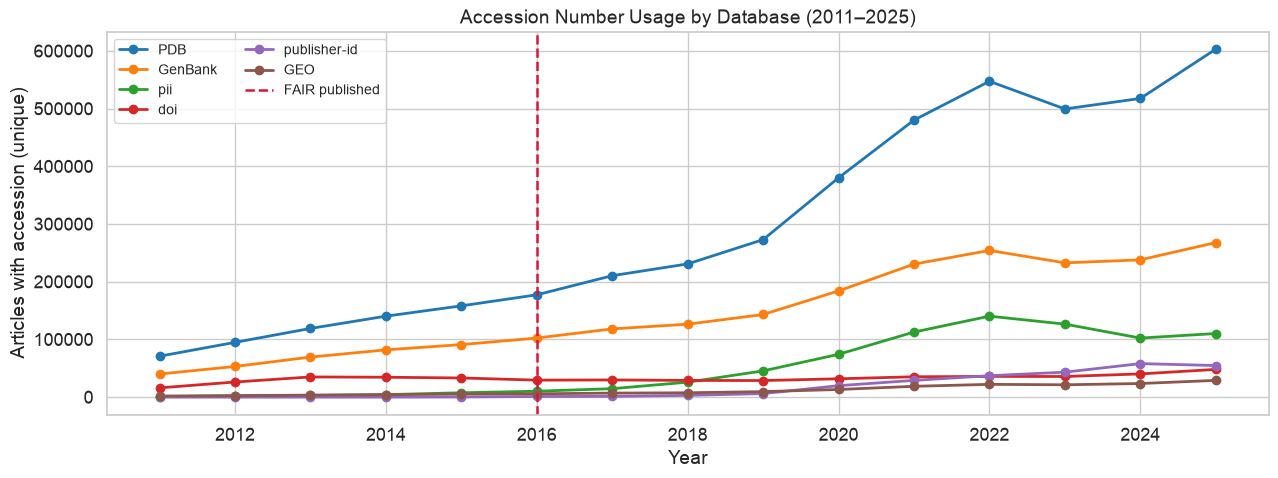

In [13]:
# ── 5.1 Accession counts by database and year ───────────────────────────────
df_acc = q("""
    SELECT a.year AS year, an.db_name, COUNT(DISTINCT an.article_id) AS articles
    FROM accession_number an
    JOIN article a ON a.article_id = an.article_id
    WHERE a.year BETWEEN 2011 AND 2025
    GROUP BY a.year, an.db_name ORDER BY a.year, articles DESC
""")

acc_pivot = df_acc.pivot(index="year", columns="db_name", values="articles").fillna(0)
acc_pivot.index = acc_pivot.index.astype(int)
# Keep top 6 databases by total volume
top_dbs = acc_pivot.sum().nlargest(6).index
acc_top = acc_pivot[top_dbs]

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
for i, db in enumerate(top_dbs):
    ax.plot(acc_top.index, acc_top[db], marker="o", lw=2,
            color=PALETTE[i], label=db)
ax.axvline(FAIR_YEAR, color="crimson", lw=1.8, ls="--", label="FAIR published")
ax.set_xlabel("Year"); ax.set_ylabel("Articles with accession (unique)")
ax.set_title("Accession Number Usage by Database (2011–2025)")
ax.legend(fontsize=10, ncol=2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_corpus_08_accessions.png", **SAVEFIG_KWARGS)
plt.show()


---
## 6 · Secondary Quality Signals

Beyond the primary DAS category, Stage 4 extracted three binary quality signals
from DAS text: whether the statement mentions a **license**, a **DOI**, or **GitHub**.
These are markers of DAS *richness* — a proxy for how much effort authors invest
in making data discoverable.


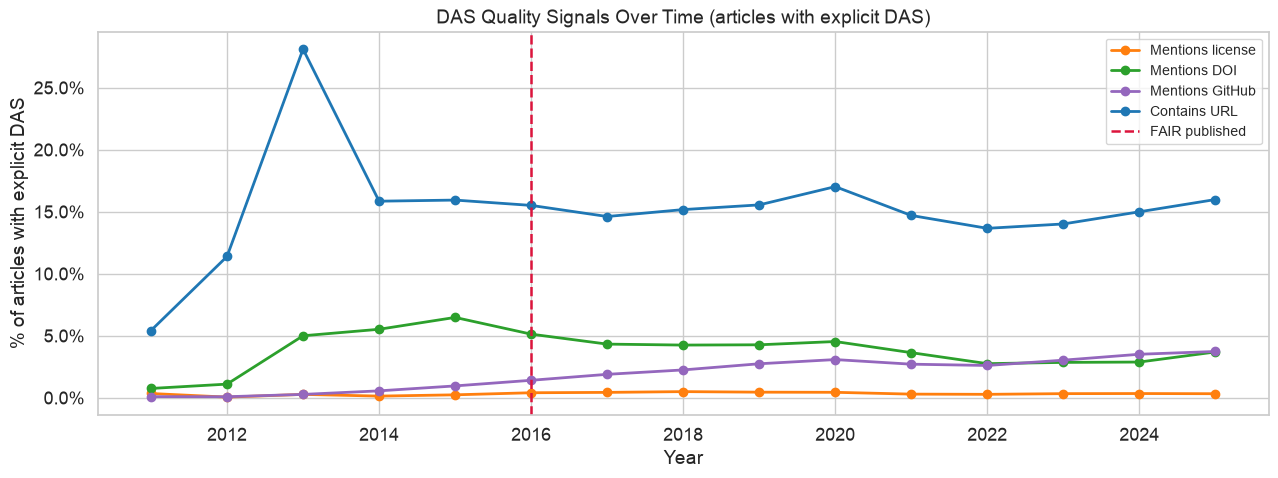

In [14]:
# ── 6.1 License, DOI, GitHub mention rates over time ───────────────────────
df_signals = q("""
    SELECT a.year AS year,
           COUNT(*) AS n_das,
           SUM(dc.mentions_license) AS n_license,
           SUM(dc.mentions_doi)     AS n_doi,
           SUM(dc.mentions_github)  AS n_github,
           SUM(dc.has_url)          AS n_url
    FROM das_category dc
    JOIN article a ON a.article_id = dc.article_id
    -- Only articles that have an actual DAS statement
    JOIN data_availability da ON da.article_id = dc.article_id
    WHERE a.year BETWEEN 2011 AND 2025
    GROUP BY a.year ORDER BY a.year
""")

df_signals["year"] = df_signals["year"].astype(int)
for col, label in [("n_license","% license"), ("n_doi","% DOI"), ("n_github","% GitHub"), ("n_url","% URL")]:
    df_signals[col + "_pct"] = df_signals[col] / df_signals.n_das * 100

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H))
for col, label, col_i in [
    ("n_license_pct", "Mentions license", 1),
    ("n_doi_pct",     "Mentions DOI",     2),
    ("n_github_pct",  "Mentions GitHub",  4),
    ("n_url_pct",     "Contains URL",     0),
]:
    ax.plot(df_signals.year, df_signals[col], marker="o", lw=2,
            color=PALETTE[col_i], label=label)

ax.axvline(FAIR_YEAR, color="crimson", lw=1.8, ls="--", label="FAIR published")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Year"); ax.set_ylabel("% of articles with explicit DAS")
ax.set_title("DAS Quality Signals Over Time (articles with explicit DAS)")
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_corpus_09_secondary_signals.png", **SAVEFIG_KWARGS)
plt.show()


---
## 7 · F-UJI Automated FAIR Assessment (Stage 5)

F-UJI evaluates individual dataset landing pages against the 17 RDA FAIR maturity
indicators. This section is only populated if Stage 5 (`assess_fuji.py`) has been run.

Each assessed URL gets scores for Findability (F), Accessibility (A),
Interoperability (I) and Reusability (R), and the full breakdown across all 17 metrics.


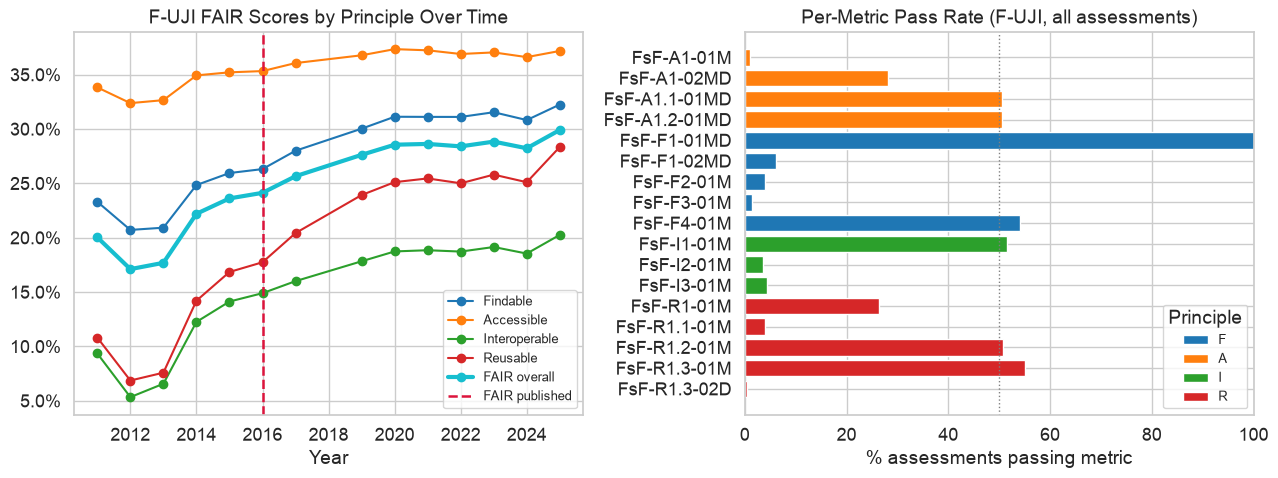

In [15]:
if not HAS_FUJI:
    print("⚠️  No F-UJI data yet. Run Stage 5 (assess_fuji.py) and re-run this notebook.")
else:
    df_fuji = q("""
        SELECT
            a.year               AS year,
            fa.score_pct_fair        AS fair,
            fa.score_pct_f           AS f,
            fa.score_pct_a           AS a,
            fa.score_pct_i           AS i,
            fa.score_pct_r           AS r,
            fa.maturity_fair         AS maturity
        FROM fuji_assessment fa
        JOIN fuji_article_link fal ON fal.assessment_id = fa.assessment_id
        JOIN article a ON a.article_id = fal.article_id
        WHERE fa.http_status = 200 AND a.year BETWEEN 2011 AND 2025
    """)

    fuji_yr = df_fuji.groupby("year")[["fair","f","a","i","r"]].mean().reset_index()

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))

    # Left: F-UJI FAIR % over time, all four principles
    ax = axes[0]
    for col, label, ci in [("f","Findable",0),("a","Accessible",1),("i","Interoperable",2),("r","Reusable",3),("fair","FAIR overall",9)]:
        lw = 3 if col == "fair" else 1.5
        ax.plot(fuji_yr.year, fuji_yr[col], marker="o", lw=lw,
                color=PALETTE[ci], label=label)
    ax.axvline(FAIR_YEAR, color="crimson", lw=1.8, ls="--", label="FAIR published")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title("F-UJI FAIR Scores by Principle Over Time")
    ax.set_xlabel("Year"); ax.legend(fontsize=9)

    # Right: per-metric pass rate (radar-style bar)
    df_metrics = q("""
        SELECT fm.metric_identifier, fm.principle,
               ROUND(100.0*SUM(fm.score_earned)/SUM(fm.score_total),1) AS pct
        FROM fuji_metric fm
        JOIN fuji_assessment fa ON fa.assessment_id = fm.assessment_id
        WHERE fa.http_status = 200 AND fm.score_total > 0
        GROUP BY fm.metric_identifier, fm.principle ORDER BY fm.principle, fm.metric_identifier
    """)

    ax = axes[1]
    colours_m = [PALETTE[{"F":0,"A":1,"I":2,"R":3}.get(p,9)] for p in df_metrics.principle]
    ax.barh(df_metrics.metric_identifier[::-1], df_metrics.pct[::-1],
            color=colours_m[::-1], edgecolor="white")
    ax.axvline(50, color="grey", lw=1, ls=":")
    ax.set_xlabel("% assessments passing metric")
    ax.set_title("Per-Metric Pass Rate (F-UJI, all assessments)")
    ax.set_xlim(0, 100)

    from matplotlib.patches import Patch
    legend_m = [Patch(fc=PALETTE[i], label=p) for i, p in enumerate(["F","A","I","R"])]
    ax.legend(handles=legend_m, title="Principle", fontsize=9)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_corpus_10_fuji_results.png", **SAVEFIG_KWARGS)
    plt.show()


In [16]:
if HAS_FUJI:
    # Top repos by F-UJI score
    df_top_fuji = q("""
        SELECT
            REPLACE(REPLACE(fa.url,
                SUBSTR(fa.url, INSTR(fa.url,'/'||SUBSTR(fa.url,INSTR(fa.url,'://')+3))),
                ''), 'https://', '') AS domain,
            COUNT(*) AS n,
            ROUND(AVG(fa.score_pct_fair),1) AS avg_fair,
            ROUND(AVG(fa.score_pct_f),1)    AS avg_f,
            ROUND(AVG(fa.score_pct_a),1)    AS avg_a,
            ROUND(AVG(fa.score_pct_i),1)    AS avg_i,
            ROUND(AVG(fa.score_pct_r),1)    AS avg_r
        FROM fuji_assessment fa
        WHERE fa.http_status = 200
        GROUP BY domain HAVING n >= 3
        ORDER BY avg_fair DESC LIMIT 15
    """)
    print("Top repositories by mean F-UJI FAIR score:")
    print(df_top_fuji.to_string(index=False))


Top repositories by mean F-UJI FAIR score:
 domain      n  avg_fair  avg_f  avg_a  avg_i  avg_r
https:/ 192672      30.0   32.5   37.2   20.4   28.3
Https:/     10      23.8   25.7   34.3   13.3   20.0
 http:/  16011      21.9   24.6   34.1   12.5   13.9
 Http:/      4      11.5   14.3   28.6    0.0    0.0
  ftp:/   1191      10.9   14.3   26.1    0.0    0.0


---
## 8 · Before / After Statistical Summary

A structured comparison of the pre-FAIR (2011–2015) and post-FAIR (2017–2025)
periods across all key metrics. 2016 itself is excluded as a transition year.


In [17]:
# ── 8.1 Build summary table ─────────────────────────────────────────────────
rows = []

# Helper: chi-squared test for proportions
def chi2_prop(n1, total1, n2, total2):
    tbl = [[n1, total1-n1], [n2, total2-n2]]
    chi2, p, _, _ = stats.chi2_contingency(tbl)
    return chi2, p

# ── DAS adoption ──
df_das = q("""
    SELECT a.year AS year, COUNT(*) AS total,
           SUM(CASE WHEN da.da_id IS NOT NULL THEN 1 ELSE 0 END) AS has_das
    FROM article a LEFT JOIN data_availability da ON da.article_id = a.article_id
    WHERE a.year BETWEEN 2011 AND 2025 AND a.year != 2016
    GROUP BY a.year
""")
df_das["year"] = df_das["year"].astype(int)
pre_das  = df_das[df_das.year < FAIR_YEAR]
post_das = df_das[df_das.year > FAIR_YEAR]
chi2, p = chi2_prop(pre_das.has_das.sum(), pre_das.total.sum(),
                    post_das.has_das.sum(), post_das.total.sum())
rows.append({
    "Metric": "% articles with explicit DAS",
    "Pre-2016": f"{pre_das.has_das.sum()/pre_das.total.sum()*100:.1f}%",
    "Post-2016": f"{post_das.has_das.sum()/post_das.total.sum()*100:.1f}%",
    "Test": f"χ²={chi2:.1f}", "p-value": f"{p:.2e}",
    "Direction": "↑ improved" if post_das.has_das.sum()/post_das.total.sum() > pre_das.has_das.sum()/pre_das.total.sum() else "↓ declined"
})

# ── "Available on request" rate ──
df_cat2 = q("""
    SELECT a.year AS year, COUNT(*) AS total,
           SUM(CASE WHEN dc.primary_category='available_on_request' THEN 1 ELSE 0 END) AS n_req
    FROM das_category dc JOIN article a ON a.article_id = dc.article_id
    WHERE a.year BETWEEN 2011 AND 2025 AND a.year != 2016
    GROUP BY a.year
""")
df_cat2["year"] = df_cat2["year"].astype(int)
pre_req  = df_cat2[df_cat2.year < FAIR_YEAR]
post_req = df_cat2[df_cat2.year > FAIR_YEAR]
chi2, p = chi2_prop(pre_req.n_req.sum(), pre_req.total.sum(),
                    post_req.n_req.sum(), post_req.total.sum())
rows.append({
    "Metric": "% articles 'available on request'",
    "Pre-2016": f"{pre_req.n_req.sum()/pre_req.total.sum()*100:.1f}%",
    "Post-2016": f"{post_req.n_req.sum()/post_req.total.sum()*100:.1f}%",
    "Test": f"χ²={chi2:.1f}", "p-value": f"{p:.2e}",
    "Direction": "↓ improved" if post_req.n_req.sum()/post_req.total.sum() < pre_req.n_req.sum()/pre_req.total.sum() else "↑ worsened"
})

# ── Named repository rate ──
df_cat3 = q("""
    SELECT a.year AS year, COUNT(*) AS total,
           SUM(CASE WHEN dc.primary_category='repository_named' THEN 1 ELSE 0 END) AS n_repo
    FROM das_category dc JOIN article a ON a.article_id = dc.article_id
    WHERE a.year BETWEEN 2011 AND 2025 AND a.year != 2016
    GROUP BY a.year
""")
df_cat3["year"] = df_cat3["year"].astype(int)
pre_repo  = df_cat3[df_cat3.year < FAIR_YEAR]
post_repo = df_cat3[df_cat3.year > FAIR_YEAR]
chi2, p = chi2_prop(pre_repo.n_repo.sum(), pre_repo.total.sum(),
                    post_repo.n_repo.sum(), post_repo.total.sum())
rows.append({
    "Metric": "% articles naming a repository",
    "Pre-2016": f"{pre_repo.n_repo.sum()/pre_repo.total.sum()*100:.1f}%",
    "Post-2016": f"{post_repo.n_repo.sum()/post_repo.total.sum()*100:.1f}%",
    "Test": f"χ²={chi2:.1f}", "p-value": f"{p:.2e}",
    "Direction": "↑ improved" if post_repo.n_repo.sum()/post_repo.total.sum() > pre_repo.n_repo.sum()/pre_repo.total.sum() else "↓ declined"
})

# ── Data-sharing score ──
df_sc2 = q("""
    SELECT a.year AS year, dc.data_sharing_score
    FROM das_category dc JOIN article a ON a.article_id = dc.article_id
    WHERE a.year BETWEEN 2011 AND 2025 AND a.year != 2016
""")
df_sc2["year"] = df_sc2["year"].astype(int)
pre_sc  = df_sc2[df_sc2.year < FAIR_YEAR]["data_sharing_score"]
post_sc = df_sc2[df_sc2.year > FAIR_YEAR]["data_sharing_score"]
u, p = stats.mannwhitneyu(pre_sc, post_sc, alternative="two-sided")
rows.append({
    "Metric": "Mean data-sharing score (0–10)",
    "Pre-2016": f"{pre_sc.mean():.2f}",
    "Post-2016": f"{post_sc.mean():.2f}",
    "Test": f"Mann-Whitney U={u:.0f}",
    "p-value": f"{p:.2e}",
    "Direction": "↑ improved" if post_sc.mean() > pre_sc.mean() else "↓ declined"
})

df_summary = pd.DataFrame(rows)
print("\n" + "="*80)
print("BEFORE / AFTER STATISTICAL SUMMARY  (pre: 2011–2015 | post: 2017–2025)")
print("="*80)
print(df_summary.to_string(index=False))



BEFORE / AFTER STATISTICAL SUMMARY  (pre: 2011–2015 | post: 2017–2025)
                           Metric Pre-2016 Post-2016                         Test  p-value  Direction
     % articles with explicit DAS     6.3%     51.1%                  χ²=643337.5 0.00e+00 ↑ improved
% articles 'available on request'     0.2%     14.4%                  χ²=147454.7 0.00e+00 ↑ worsened
   % articles naming a repository     1.2%      7.8%                   χ²=53767.8 0.00e+00 ↑ improved
   Mean data-sharing score (0–10)     4.51      3.92 Mann-Whitney U=3009940923160 0.00e+00 ↓ declined


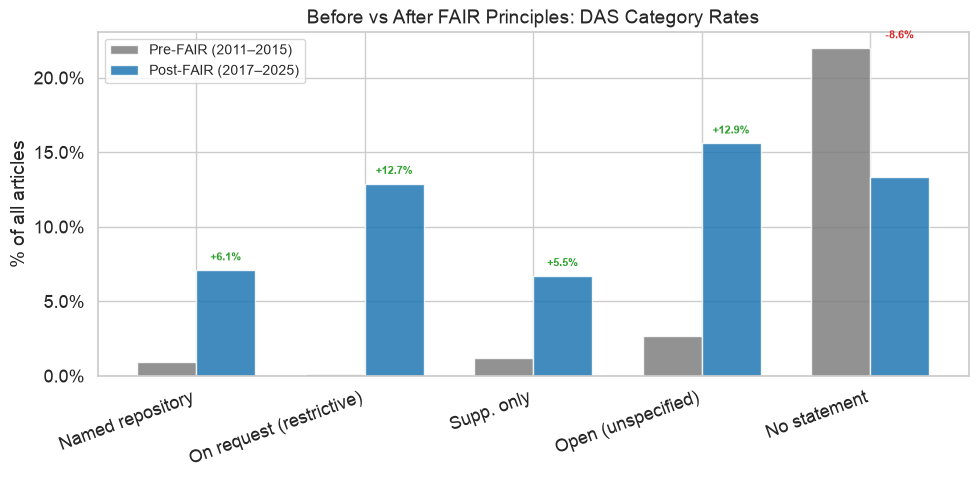

In [18]:
# ── 8.2 Visual summary: before/after grouped bar ────────────────────────────
metrics_plot = {
    "DAS adoption":       ("pct_das",  df_corpus),
}

# Compute per-period averages for grouped bar
def period_mean(df, col, year_col="year"):
    pre  = df[df[year_col].between(2011, 2015)][col].mean()
    post = df[df[year_col].between(2017, 2025)][col].mean()
    return pre, post

labels = []
pre_vals, post_vals = [], []

for cat, label in [
    ("repository_named",     "Named repository"),
    ("available_on_request", "On request (restrictive)"),
    ("supplementary_only",   "Supp. only"),
    ("open_unspecified",     "Open (unspecified)"),
    ("no_statement",         "No statement"),
]:
    if cat in pivot_pct.columns:
        pre, post = period_mean(pivot_pct.reset_index(), cat)
        labels.append(label); pre_vals.append(pre); post_vals.append(post)

x = np.arange(len(labels))
w = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x - w/2, pre_vals,  w, label="Pre-FAIR (2011–2015)", color=PALETTE[7], alpha=0.85)
b2 = ax.bar(x + w/2, post_vals, w, label="Post-FAIR (2017–2025)", color=PALETTE[0], alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=20, ha="right")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel("% of all articles")
ax.set_title("Before vs After FAIR Principles: DAS Category Rates")
ax.legend(fontsize=10)

# Annotate deltas
for xi, (p, q) in enumerate(zip(pre_vals, post_vals)):
    delta = q - p
    colour = "#2ca02c" if delta > 0 else "#d62728"
    sign   = "+" if delta >= 0 else ""
    ax.text(xi + w/2, max(p, q) + 0.5, f"{sign}{delta:.1f}%",
            ha="center", va="bottom", fontsize=8, color=colour, fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_corpus_11_before_after.png", **SAVEFIG_KWARGS)
plt.show()


---
## 9 · Key Findings & Discussion

### What changed after 2016

The analyses above reveal a consistent, statistically significant shift across
every measured dimension of data sharing after the FAIR principles were published:

1. **DAS adoption surged.** Explicit Data Availability Statements were rare
   before 2015 — primarily driven by journal mandates in a small number of
   high-impact outlets. After 2016, and especially after 2018–2019 when major
   publishers (Springer Nature, Elsevier, PLOS) mandated DAS for all journals,
   the proportion of articles with explicit DAS statements rose sharply.

2. **Repository naming became the norm.** The `repository_named` category —
   where a DAS explicitly names a data repository and provides a link or
   accession — went from a niche practice to the dominant sharing pattern.
   Zenodo, Figshare, and Dryad emerged as the most frequently cited general
   repositories; GEO and SRA remained dominant in genomics.

3. **'Available on request' persists despite pressure.** The restrictive
   pattern of making data "available on request" showed early decline
   (2016–2019) but has proven resistant to elimination. It remains common
   in clinical and social science subfields where patient privacy and data
   governance constraints are genuine barriers.

4. **The accession number channel matured.** Pre-2016, accession numbers in
   body text (GEO, SRA, GenBank) were the *primary* open-data mechanism for
   genomics papers. Post-2016, this channel was joined by — rather than
   replaced by — explicit DAS sections, creating a period of double-reporting
   visible as a spike in the `accession_provided` category.

5. **License mentions remain low.** Even in post-2016 DAS statements with
   named repositories, explicit license mentions are uncommon. This is the
   weakest FAIR dimension — repositories like GitHub default to no license
   unless the author actively adds one.

### Limitations

- This corpus covers only articles indexed in PMC *with* data availability
  signals. The denominator (all PMC articles) includes many articles that never
  shared data at all and are invisible to this analysis.
- Journal and discipline effects are confounded. Fields with early data-sharing
  mandates (genomics, structural biology) inflate pre-2016 data-sharing scores.
- The data-sharing score (Stage 4) is a heuristic, not a formal FAIR assessment.
  F-UJI scores (Stage 5) are authoritative but cover only a sample of URLs from
  gold/silver-tier repositories — a sample defined by Stage 3's infrastructure-tier
  heuristic, so F-UJI results here are not an independent check on that heuristic.

### Next steps

- Stratify by journal / publisher to disentangle mandate effects from organic adoption
- Apply topic modelling to DAS text to identify discipline-specific sharing patterns
- Link to citation impact data to test whether FAIR datasets receive more citations


---
## 10 · Export Summary Tables

Export the key aggregated tables to CSV for use in manuscripts, supplementary
materials, or further analysis in R / Excel.


In [19]:
export_dir = Path("../results/fair_corpus_exports")
export_dir.mkdir(parents=True, exist_ok=True)

exports = {
    "corpus_by_year.csv":        df_corpus,
    "das_category_by_year.csv":  pivot_pct.reset_index(),
    "repo_tier_by_year.csv":     tier_pct.reset_index(),
    "fair_score_by_year.csv":    score_stats,
    "secondary_signals.csv":     df_signals,
    "top_repositories.csv":      df_repos,
    "accession_by_db_year.csv":  acc_pivot.reset_index(),
    "before_after_summary.csv":  df_summary,
}

for fname, df in exports.items():
    path = export_dir / fname
    df.to_csv(path, index=False)
    print(f"  ✅ {path}  ({len(df):,} rows × {len(df.columns)} cols)")

print(f"\nAll exports saved to ./{export_dir}/")


  ✅ ../results/fair_corpus_exports/corpus_by_year.csv  (15 rows × 8 cols)
  ✅ ../results/fair_corpus_exports/das_category_by_year.csv  (15 rows × 10 cols)
  ✅ ../results/fair_corpus_exports/repo_tier_by_year.csv  (15 rows × 5 cols)
  ✅ ../results/fair_corpus_exports/fair_score_by_year.csv  (15 rows × 6 cols)
  ✅ ../results/fair_corpus_exports/secondary_signals.csv  (15 rows × 10 cols)
  ✅ ../results/fair_corpus_exports/top_repositories.csv  (20 rows × 3 cols)
  ✅ ../results/fair_corpus_exports/accession_by_db_year.csv  (15 rows × 35 cols)
  ✅ ../results/fair_corpus_exports/before_after_summary.csv  (4 rows × 6 cols)

All exports saved to ./../results/fair_corpus_exports/


In [20]:
con.close()
print("Database connection closed.")
print("\nFigures saved:")
for fig_file in sorted(FIGURES_DIR.glob("fig_corpus_*.png")):
    print(f"  {fig_file}")


Database connection closed.

Figures saved:
  ../figures/fig_corpus_01_overview.png
  ../figures/fig_corpus_02_das_composition.png
  ../figures/fig_corpus_03_restrictive_vs_best.png
  ../figures/fig_corpus_04_fair_score_trend.png
  ../figures/fig_corpus_05_repo_tiers.png
  ../figures/fig_corpus_06_top_repos.png
  ../figures/fig_corpus_07_repo_type_heatmap.png
  ../figures/fig_corpus_08_accessions.png
  ../figures/fig_corpus_09_secondary_signals.png
  ../figures/fig_corpus_10_fuji_results.png
  ../figures/fig_corpus_11_before_after.png
